# Chapter 3 — Classification: MNIST
## The "Hello World" of Machine Learning

- **Dataset**: 70,000 grayscale images ($28 \times 28$ pixels $= 784$ features) of handwritten digits (0–9).
- **Pixel values**: Range from `0` (white background) to `255` (black ink).
- **Goal**: Transition from regression (predicting continuous prices) to **classification** (predicting discrete categories).


## 1. Setup & Starter Imports

Key imports for plotting, data handling, and classification metrics:

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Scikit-Learn models, tools & metrics
from sklearn.utils import Bunch
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
    roc_auc_score,
)

%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)
np.random.seed(42)

print("Setup complete!")

Setup complete!


## 2. Load MNIST (Fast Local Cache / Mirror)

> 📌 **Book Note (OpenML issue):** `fetch_openml('mnist_784')` frequently times out due to server congestion. The helper below uses a cached `../data/mnist.npz` (Google mirror) and returns a Scikit-Learn `Bunch` with identical keys.

In [2]:
def load_mnist():
    data_dir = os.path.join("..", "data")
    os.makedirs(data_dir, exist_ok=True)
    mnist_path = os.path.join(data_dir, "mnist.npz")
    
    if not os.path.exists(mnist_path):
        url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
        urllib.request.urlretrieve(url, mnist_path)
    
    with np.load(mnist_path) as npz:
        x_train, y_train = npz["x_train"], npz["y_train"]
        x_test, y_test = npz["x_test"], npz["y_test"]
    
    X = np.concatenate([x_train.reshape(-1, 784), x_test.reshape(-1, 784)], axis=0)
    y = np.concatenate([y_train.astype(str), y_test.astype(str)], axis=0)
    
    return Bunch(data=X, target=y, DESCR="MNIST 70k 28x28 digits")

mnist = load_mnist()
X, y = mnist["data"], mnist["target"]
print(f"X shape: {X.shape} | y shape: {y.shape}")

X shape: (70000, 784) | y shape: (70000,)


## 3. Visualizing Digits

Reshape any 784-dim vector into a $28 \times 28$ array and display with `plt.imshow(cmap="binary")`:

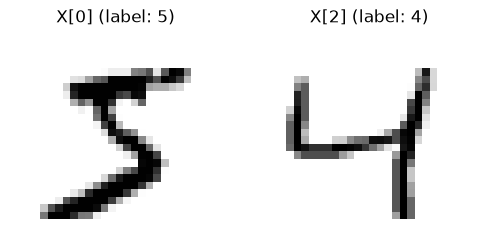

In [3]:
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

# Inspect sample 0 (digit 5) and sample 2 (digit 4)
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X[0].reshape(28, 28), cmap="binary")
axes[0].set_title(f"X[0] (label: {y[0]})")
axes[0].axis("off")

axes[1].imshow(X[2].reshape(28, 28), cmap="binary")
axes[1].set_title(f"X[2] (label: {y[2]})")
axes[1].axis("off")
plt.show()

## 4. Train / Test Split

- MNIST is already pre-split: first **60,000** = train set, last **10,000** = test set.
- Cast string labels to integers (`np.uint8`).

In [4]:
y = y.astype(np.uint8)

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

print(f"Train set: {X_train.shape} | Test set: {X_test.shape}")

Train set: (60000, 784) | Test set: (10000, 784)


## 5. Training a Binary Classifier (The "5-Detector")

Simplify to a binary problem: distinguish between **5** and **not-5**.
- `SGDClassifier`: Uses **Stochastic Gradient Descent**. Efficient for large datasets because it processes instances one-by-one.

In [5]:
# Create boolean target vectors: True for all 5s, False for other digits
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

# Test predictions on a 5 (X[0]) and a 4 (X[2])
print("Predict X[0] (is a 5): ", sgd_clf.predict([X[0]]))
print("Predict X[2] (is a 4): ", sgd_clf.predict([X[2]]))

Predict X[0] (is a 5):  [ True]
Predict X[2] (is a 4):  [False]


### Custom Implementation of Cross-Validation (Under the Hood)

Occasionally you need more control over cross-validation than `cross_val_score()` provides off-the-shelf. This loop shows what happens under the hood.

#### 💡 What the Inputs Mean:
- `n_splits=3`: Divides the 60,000 training images into **3 equal folds** (20,000 images per fold).
- `shuffle=True`: Shuffles the dataset indices before splitting so digits are mixed randomly across folds.
- `random_state=42`: Seed number ensuring the shuffle produces the exact same fold partitions every time.
- `skfolds.split(X_train, y_train_5)`:
  - Takes the features (`X_train`) and labels (`y_train_5`).
  - **Why pass `y_train_5`?** Because it is *Stratified*! It must inspect the labels to guarantee each fold contains the exact same ratio of 5s (~10%) and non-5s (~90%).
- `clone(sgd_clf)`: Creates a brand-new, untrained replica of the model with the exact same hyperparameters so each fold starts fresh with no memory leakage.

> ⚠️ **Why the book's original code broke (`ValueError`):**
> In older Scikit-Learn versions, `StratifiedKFold(n_splits=3, random_state=42)` allowed `random_state` with default `shuffle=False`. Modern Scikit-Learn raises an error because a random seed does nothing without `shuffle=True`.

In [6]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# 1. Configure 3 stratified folds (shuffle=True enables random_state=42)
skfolds = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. skfolds.split() yields row indices for training (40k samples) and testing (20k samples)
for train_index, test_index in skfolds.split(X_train, y_train_5):
    # clone() creates a fresh, untrained copy of the model with identical settings
    clone_clf = clone(sgd_clf)
    
    # Slice out 2 folds for training (40,000 images and boolean labels)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    
    # Slice out 1 fold for validation (20,000 images and boolean labels)
    X_test_fold = X_train[test_index]
    y_test_fold = y_train_5[test_index]
    
    # Train the fresh clone on the 40k training samples
    clone_clf.fit(X_train_folds, y_train_folds)
    
    # Evaluate predictions on the 20k unseen validation samples
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    
    # Print the accuracy score for this specific fold
    print(f"Fold Accuracy: {n_correct / len(y_pred):.4f}")


Fold Accuracy: 0.9042


Fold Accuracy: 0.9477


Fold Accuracy: 0.9678


## 6. Measuring Accuracy & The Accuracy Trap

- Evaluating `SGDClassifier` using 3-fold cross-validation gives **~95-96% accuracy**.
- **The Trap**: Only ~10% of the images are 5s (90% are not 5s). A dumb classifier (`DummyClassifier`) that *always* predicts `False` ("never-5") achieves **~90% accuracy**!

> ⚠️ **Golden Rule:** **Accuracy is often misleading on skewed/imbalanced datasets.** Never rely on accuracy alone.

In [7]:
# 1. 3-Fold Cross-Validation on SGD Classifier
sgd_acc_scores = cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(f"SGD Classifier CV Accuracy:   {sgd_acc_scores.round(4)} (Mean: {sgd_acc_scores.mean():.2%})")

# 2. Baseline Dummy Classifier (always predicts most frequent class -> False)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_acc_scores = cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(f"Dumb 'Never-5' Model Accuracy: {dummy_acc_scores.round(4)} (Mean: {dummy_acc_scores.mean():.2%})")

SGD Classifier CV Accuracy:   [0.9504 0.9604 0.9604] (Mean: 95.70%)
Dumb 'Never-5' Model Accuracy: [0.9096 0.9096 0.9096] (Mean: 90.96%)


## 7. Confusion Matrix

Counts how many times instances of class A were classified as class B.
- `cross_val_predict`: Generates clean out-of-fold predictions on the training set.

| | Predicted Negative (Not 5) | Predicted Positive (5) |
| :--- | :---: | :---: |
| **Actual Negative (Not 5)** | **True Negative (TN)** | **False Positive (FP)** (Type I) |
| **Actual Positive (5)** | **False Negative (FN)** (Type II) | **True Positive (TP)** |

In [8]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)

print("Confusion Matrix:")
print(cm)
print(f"\nTN (correct non-5s): {cm[0, 0]} | FP (wrongly called 5): {cm[0, 1]}")
print(f"FN (missed 5s):      {cm[1, 0]}  | TP (correctly detected 5s): {cm[1, 1]}")

Confusion Matrix:
[[53892   687]
 [ 1891  3530]]

TN (correct non-5s): 53892 | FP (wrongly called 5): 687
FN (missed 5s):      1891  | TP (correctly detected 5s): 3530


## 8. Precision, Recall, and $F_1$ Score

- **Precision** $= \frac{TP}{TP + FP}$: Accuracy of positive predictions (*"When it says it's a 5, is it right?"*)
- **Recall (Sensitivity)** $= \frac{TP}{TP + FN}$: Completeness (*"What fraction of all actual 5s did it find?"*)
- **$F_1$ Score** $= 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$: Harmonic mean (punishes models where one metric is very low).

In [9]:
prec = precision_score(y_train_5, y_train_pred)
rec = recall_score(y_train_5, y_train_pred)
f1 = f1_score(y_train_5, y_train_pred)

print(f"Precision: {prec:.4f} ({prec:.2%})")
print(f"Recall:    {rec:.4f} ({rec:.2%})")
print(f"F1 Score:  {f1:.4f} ({f1:.2%})")
print("\nSummary: When it claims an image is a 5, it is right ~83.7% of the time, but it only catches ~65.1% of all 5s.")

Precision: 0.8371 (83.71%)
Recall:    0.6512 (65.12%)
F1 Score:  0.7325 (73.25%)

Summary: When it claims an image is a 5, it is right ~83.7% of the time, but it only catches ~65.1% of all 5s.


## 9. The ROC Curve

The **Receiver Operating Characteristic (ROC)** curve plots the **True Positive Rate (TPR / Recall)** against the **False Positive Rate (FPR)** across all possible decision thresholds.

- **FPR** is the ratio of negative instances incorrectly classified as positive:
$$\text{FPR} = \frac{FP}{TN + FP} = 1 - \text{Specificity (TNR)}$$

- **TPR (Recall / Sensitivity)** is the ratio of positive instances correctly detected:
$$\text{TPR} = \frac{TP}{TP + FN}$$

> 📌 **Key Intuition:** The dashed diagonal line represents a purely random classifier ($\text{AUC} = 0.5$). A good classifier stays as far away from that line as possible—pushing toward the top-left corner ($\text{AUC} \to 1.0$).

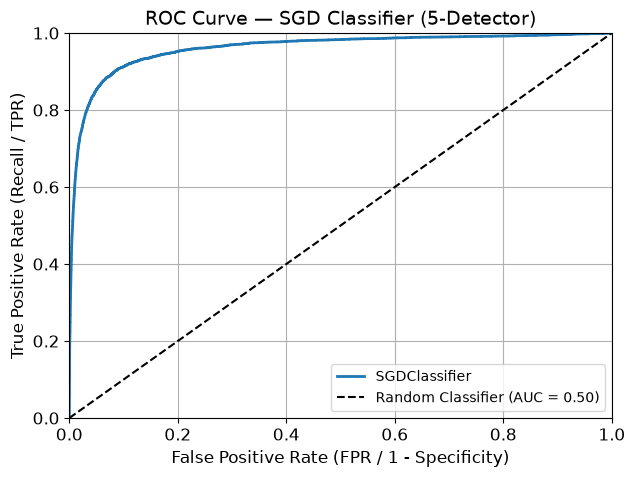

ROC AUC Score: 0.9605 (96.05%)


In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Get decision scores (not boolean labels) for all training instances via cross-validation
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")

# 2. Compute FPR, TPR (Recall), and thresholds
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

# 3. Plot ROC curve function
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier (AUC = 0.50)")  # dashed diagonal
    plt.axis([0, 1, 0, 1])
    plt.xlabel("False Positive Rate (FPR / 1 - Specificity)", fontsize=12)
    plt.ylabel("True Positive Rate (Recall / TPR)", fontsize=12)
    plt.title("ROC Curve — SGD Classifier (5-Detector)", fontsize=14)
    plt.grid(True)
    if label:
        plt.legend(loc="lower right")

# 4. Display the curve
plt.figure(figsize=(7, 5))
plot_roc_curve(fpr, tpr, label="SGDClassifier")
plt.show()

# 5. Measure Area Under the Curve (ROC AUC)
auc_score = roc_auc_score(y_train_5, y_scores)
print(f"ROC AUC Score: {auc_score:.4f} ({auc_score:.2%})")

### Key Takeaways from the ROC Curve

1. **The Core Trade-off**:
   - As Recall (TPR) increases, the False Positive Rate (FPR) also inevitably rises.
   - You cannot catch more true 5s without accepting more non-5 images wrongly flagged as 5s.

2. **The Ideal Position (Top-Left Corner)**:
   - A perfect classifier hits the top-left corner: **100% Recall (TPR = 1.0)** with **0% False Alarms (FPR = 0.0)**.
   - The closer the curve arches toward the top-left corner, the better the model performs.

3. **Baseline (Dashed Diagonal)**:
   - The diagonal 45° line represents a **purely random classifier** (a 50/50 coin flip, $\text{AUC} = 0.50$).
   - A good model stays as far above this line as possible.

4. **ROC AUC Score ($0.9605$)**:
   - Quantifies the entire curve into a single number between $0.5$ (random) and $1.0$ (perfect).
   - A score of **~96%** means the classifier gives a higher predicted score to a randomly chosen positive sample than a randomly chosen negative sample 96% of the time.

> ⚠️ **Golden Rule: When to Use ROC vs. Precision-Recall (PR) Curve**:
> - **Use PR Curve**: When the positive class is **rare/imbalanced** (like our 5s dataset, fraud, disease) or when you care much more about avoiding false positives (false alarms).
> - **Use ROC Curve**: When classes are roughly **balanced** or when false negatives are equally or more critical.
> *(Notice: The ROC curve looks deceptively great at 96% AUC because the 90% non-5s make the denominator $TN + FP$ huge, keeping FPR small!)*

ROC vs PR

In [23]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3,
    method="predict_proba")

KeyboardInterrupt: 